# Energy Efficiency Prediction with Deep Learning


## 1. Setup and Data Loading

In [1]:
# import libraries
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns

from ucimlrepo import fetch_ucirepo 


In [ ]:
energy_efficiency = fetch_ucirepo(id=242) 
X = energy_efficiency.data.features
y = energy_efficiency.data.targets

## 2. Inspect and Prepare the Dataset

In [8]:
print('FEATURE shape:', X.shape)
print('TARGET shape:', y.shape)

FEATURE shape: (768, 8)
TARGET shape: (768, 2)


In [14]:
X.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 8 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   X1      768 non-null    float64
 1   X2      768 non-null    float64
 2   X3      768 non-null    float64
 3   X4      768 non-null    float64
 4   X5      768 non-null    float64
 5   X6      768 non-null    int64  
 6   X7      768 non-null    float64
 7   X8      768 non-null    int64  
dtypes: float64(6), int64(2)
memory usage: 48.1 KB


In [16]:
X.columns = np.array(['Relative Compactness', 'Surface Area', 'Wall Area', 'Roof Area', 'Overall Height', 'Orientation', 'Glazing Area', 'Glazing Area Distribution'])

In [18]:
y.columns = np.array(['Heating Load', 'Cooling Load'])

### Preview and Summary Statistics

In [22]:
X.head()

,Relative Compactness,Surface Area,Wall Area,Roof Area,Overall Height,Orientation,Glazing Area,Glazing Area Distribution
0,0.98,514.5,294.0,110.25,7.0,2,0.0,0
1,0.98,514.5,294.0,110.25,7.0,3,0.0,0
2,0.98,514.5,294.0,110.25,7.0,4,0.0,0
3,0.98,514.5,294.0,110.25,7.0,5,0.0,0
4,0.90,563.5,318.5,122.50,7.0,2,0.0,0


In [20]:
X.describe()

,Relative Compactness,Surface Area,Wall Area,Roof Area,Overall Height,Orientation,Glazing Area,Glazing Area Distribution
count,768.000000,768.000000,768.000000,768.000000,768.00000,768.000000,768.000000,768.00000
mean,0.764167,671.708333,318.500000,176.604167,5.25000,3.500000,0.234375,2.81250
std,0.105777,88.086116,43.626481,45.165950,1.75114,1.118763,0.133221,1.55096
min,0.620000,514.500000,245.000000,110.250000,3.50000,2.000000,0.000000,0.00000
25%,0.682500,606.375000,294.000000,140.875000,3.50000,2.750000,0.100000,1.75000
50%,0.750000,673.750000,318.500000,183.750000,5.25000,3.500000,0.250000,3.00000
75%,0.830000,741.125000,343.000000,220.500000,7.00000,4.250000,0.400000,4.00000
max,0.980000,808.500000,416.500000,220.500000,7.00000,5.000000,0.400000,5.00000


In [21]:
y.describe()

,Heating Load,Cooling Load
count,768.000000,768.000000
mean,22.307201,24.587760
std,10.090196,9.513306
min,6.010000,10.900000
25%,12.992500,15.620000
50%,18.950000,22.080000
75%,31.667500,33.132500
max,43.100000,48.030000


## 3. Exploratory Data Analysis

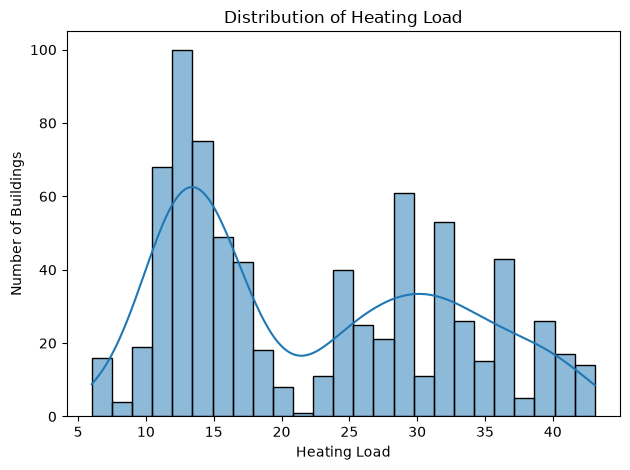

In [39]:
fig, ax = plt.subplots()

sns.histplot(data=y, x='Heating Load', kde=True, bins=25, cbar=True, ax=ax)
ax.set_title("Distribution of Heating Load")
ax.set_xlabel("Heating Load")
ax.set_ylabel("Number of Buildings")
plt.tight_layout()
plt.show()


In [43]:
rel_data = X.copy()
rel_data['Heating Load'] = y['Heating Load']

### Feature Correlations

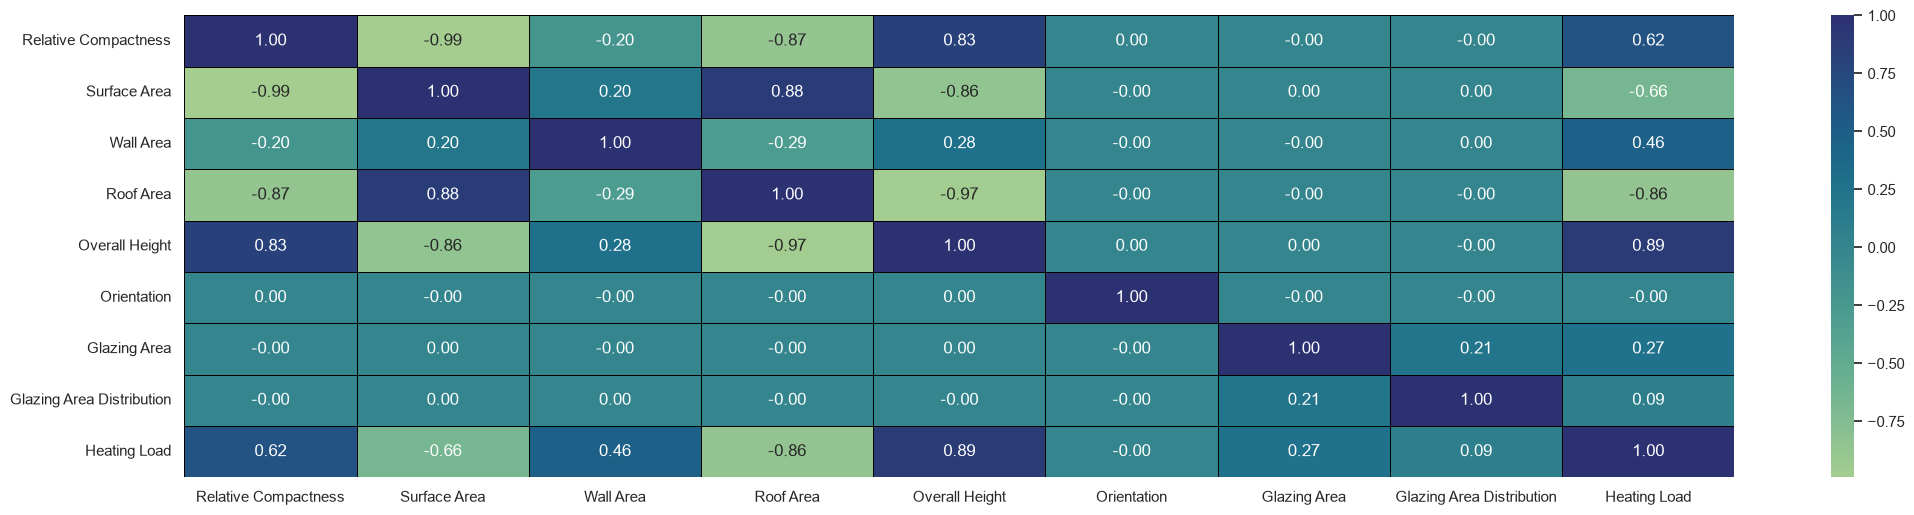

In [ ]:
corr = rel_data.corr(numeric_only=True)

sns.set_theme(context='notebook', style='darkgrid', palette='deep')
fig = plt.figure(figsize=(25, 6))
ax = sns.heatmap(data=corr, annot=True, fmt='.2f', linewidths=0.5 , linecolor='black', cmap='crest')

### Feature Relationships with Heating Load

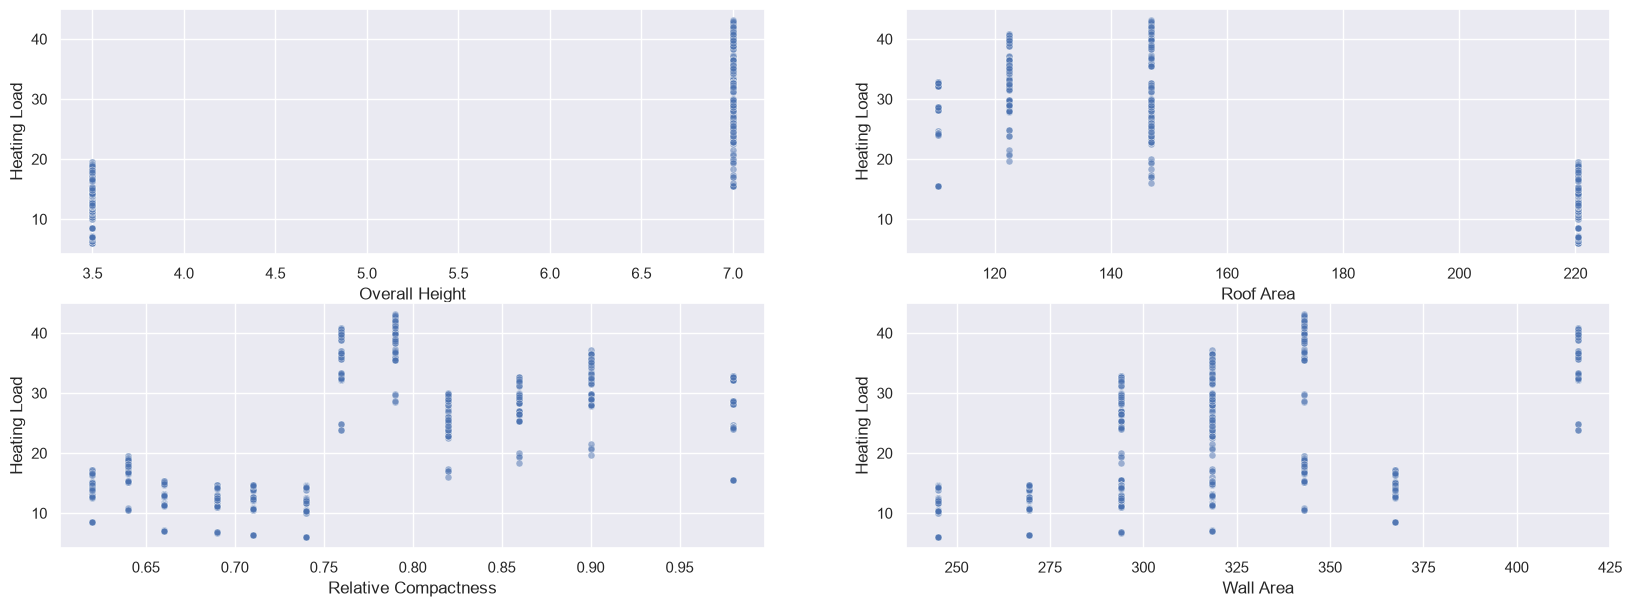

In [117]:
features_to_plot = [
    "Overall Height",
    "Roof Area",
    "Relative Compactness",
    "Wall Area",
]
fig, axes = plt.subplots(2, 2, figsize=(20, 7))

for ax, feat in zip(axes.ravel(), features_to_plot):
    sns.scatterplot(
    data=rel_data,
    x=feat,
    y="Heating Load",
    alpha=0.5,
    s=25,
    ax=ax
)

## 4. Train/Test Split and Linear Regression Baseline

In [143]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = X.copy()
TARGET = y['Heating Load'].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X,
    TARGET,
    test_size=0.2,
    random_state=42
)

scaler = StandardScaler()

x_train_sc = scaler.fit_transform(X_train)
x_test_sc = scaler.transform(X_test)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])
print("Scaled training shape:", x_train_sc.shape)
print("Scaled testing shape:", x_test_sc.shape)

Training samples: 614
Testing samples: 154
Scaled training shape: (614, 8)
Scaled testing shape: (154, 8)


In [146]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

baseline_model = LinearRegression()
baseline_model.fit(x_train_sc, y_train)

y_train_pred = baseline_model.predict(x_train_sc)
y_test_pred = baseline_model.predict(x_test_sc)

def evaluate_regression(y_true, y_pred, dataset_name):
    
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)

    print(f"{dataset_name} results:")
    print(f"MAE:  {mae:.4f}")
    print(f"RMSE: {rmse:.4f}")
    print(f"R²:   {r2:.4f}")
    print('\n')

evaluate_regression(y_train, y_train_pred, "Train")
evaluate_regression(y_test, y_test_pred, "Test")

Train results:
MAE:  2.0414
RMSE: 2.8931
R²:   0.9171


Test results:
MAE:  2.1820
RMSE: 3.0254
R²:   0.9122




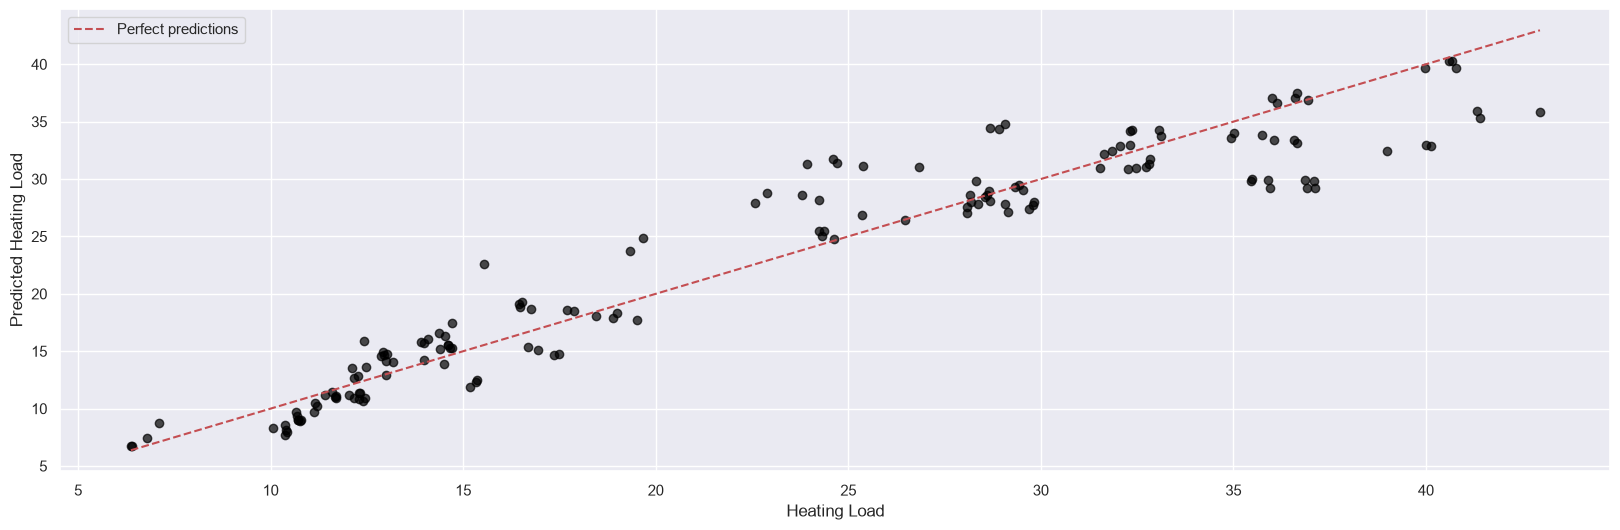

In [ ]:
fig = plt.figure(figsize=(20, 6))
ax = fig.subplots()

ax.scatter(y_test, y_test_pred, alpha=0.7, c='black')

limits = [
    min(y_test.min(), y_test_pred.min()),
    max(y_test.max(), y_test_pred.max())
]
ax.plot(limits, limits, "r--", label="Perfect predictions")
ax.set_xlabel('Heating Load')
ax.set_ylabel('Predicted Heating Load')
plt.legend()
plt.show()

## 5. Multilayer Perceptron (MLP) Regression

In [152]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Reproducibility
tf.keras.utils.set_random_seed(42)

# Build the MLP
model = keras.Sequential([
    layers.Input(shape=(x_train_sc.shape[1],)),
    layers.Dense(64, activation="relu"),
    layers.Dense(32, activation="relu"),
    layers.Dense(1)
])

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="mse",
    metrics=["mae"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,689 (10.50 KB)

 Trainable params: 2,689 (10.50 KB)

 Non-trainable params: 0 (0.00 B)

### Training with Early Stopping

In [153]:
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=30,
    restore_best_weights=True
)

history = model.fit(
    x_train_sc,
    y_train,
    validation_split=0.2,
    epochs=500,
    batch_size=32,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/500
16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - loss: 593.6201 - mae: 22.1164 - val_loss: 515.9567 - val_mae: 20.5928
Epoch 2/500
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 554.2993 - mae: 21.2045 - val_loss: 475.6785 - val_mae: 19.5852
Epoch 3/500
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 506.3022 - mae: 20.0559 - val_loss: 422.4775 - val_mae: 18.2215
Epoch 4/500
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 442.3042 - mae: 18.4764 - val_loss: 351.2930 - val_mae: 16.3110
Epoch 5/500
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 356.5685 - mae: 16.2347 - val_loss: 261.0893 - val_mae: 13.6747
Epoch 6/500
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 253.9894 - mae: 13.2443 - val_loss: 164.9390 - val_mae: 10.3977
Epoch 7/500
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 152.0411 - mae: 9.6680 - val_loss: 85.1218 - val_mae: 6.8475
Epoch 8/500
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 76.4569 - mae: 6.3092 - val_loss: 43.0697 - val_mae: 4.5524
Epoch 9/500
16/16 ━━━━

### Training History

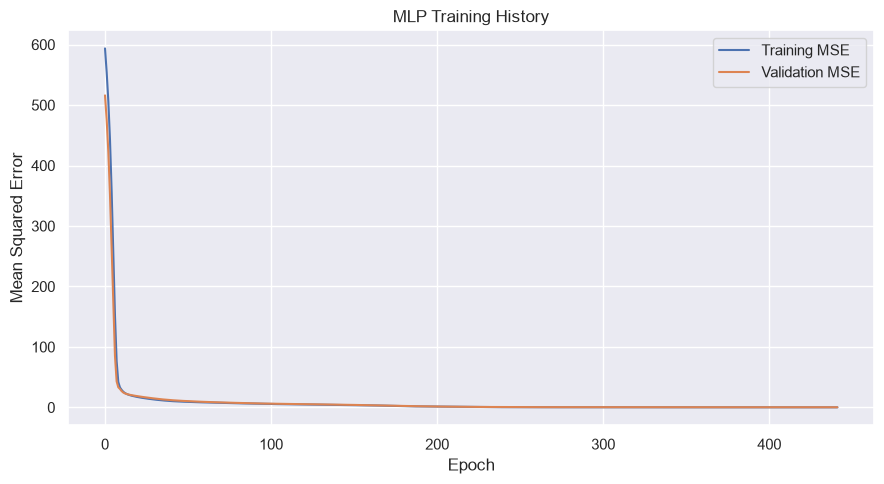

In [154]:
fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(history.history["loss"], label="Training MSE")
ax.plot(history.history["val_loss"], label="Validation MSE")

ax.set_title("MLP Training History")
ax.set_xlabel("Epoch")
ax.set_ylabel("Mean Squared Error")
ax.legend()

plt.tight_layout()
plt.show()

### Test-Set Predictions and Metrics

In [155]:
y_train_mlp_pred = model.predict(x_train_sc, verbose=0).ravel()
y_test_mlp_pred = model.predict(x_test_sc, verbose=0).ravel()

evaluate_regression(y_train, y_train_mlp_pred, "MLP Train")
evaluate_regression(y_test, y_test_mlp_pred, "MLP Test")

MLP Train results:
MAE:  0.2886
RMSE: 0.3925
R²:   0.9985


MLP Test results:
MAE:  0.3923
RMSE: 0.5060
R²:   0.9975




### Actual vs. Predicted Heating Load

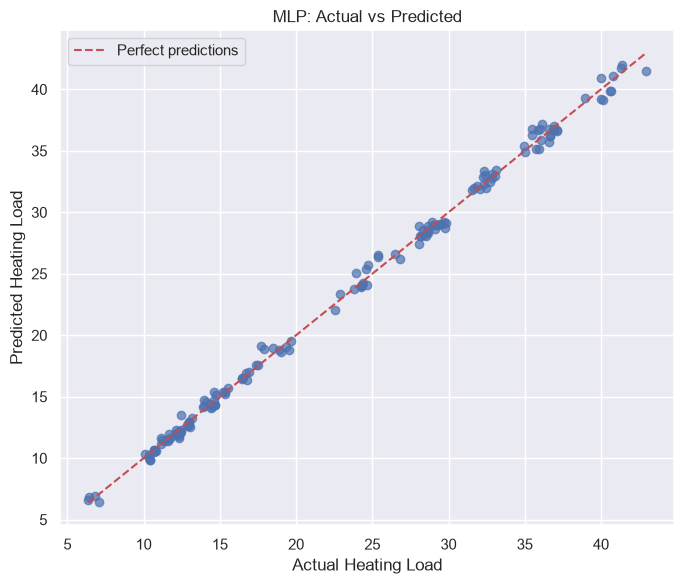

In [156]:
fig, ax = plt.subplots(figsize=(7, 6))

ax.scatter(y_test, y_test_mlp_pred, alpha=0.7)

limits = [
    min(y_test.min(), y_test_mlp_pred.min()),
    max(y_test.max(), y_test_mlp_pred.max())
]

ax.plot(limits, limits, "r--", label="Perfect predictions")

ax.set_xlabel("Actual Heating Load")
ax.set_ylabel("Predicted Heating Load")
ax.set_title("MLP: Actual vs Predicted")
ax.legend()

plt.tight_layout()
plt.show()

## 6. Feature Ablation

In [158]:
# Convert feature sets to DataFrames for comparison
train_features = X_train.copy()
test_features = X_test.copy()

# Count test rows that also appear in training features
train_rows = set(map(tuple, train_features.to_numpy()))
test_rows = list(map(tuple, test_features.to_numpy()))

overlap_count = sum(row in train_rows for row in test_rows)

print("Test samples:", len(test_rows))
print("Test rows also present in train:", overlap_count)
print("Overlap percentage:", f"{100 * overlap_count / len(test_rows):.2f}%")

Test samples: 154
Test rows also present in train: 0
Overlap percentage: 0.00%


## 7. Five-Fold Cross-Validation

In [159]:

from sklearn.model_selection import KFold

def build_mlp(input_dim):
    model = keras.Sequential([
        layers.Input(shape=(input_dim,)),
        layers.Dense(64, activation="relu"),
        layers.Dense(32, activation="relu"),
        layers.Dense(1)
    ])

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.001),
        loss="mse"
    )

    return model

In [160]:
X_cv = X.to_numpy(dtype=np.float32)
y_cv = y["Heating Load"].to_numpy(dtype=np.float32)

kf = KFold(n_splits=5, shuffle=True, random_state=42)

fold_results = []

for fold, (train_idx, val_idx) in enumerate(kf.split(X_cv), start=1):
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(42 + fold)

    X_fold_train = X_cv[train_idx]
    X_fold_val = X_cv[val_idx]

    y_fold_train = y_cv[train_idx]
    y_fold_val = y_cv[val_idx]

    scaler = StandardScaler()
    X_fold_train = scaler.fit_transform(X_fold_train)
    X_fold_val = scaler.transform(X_fold_val)

    model_cv = build_mlp(X_fold_train.shape[1])

    early_stopping = keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=30,
        restore_best_weights=True
    )

    model_cv.fit(
        X_fold_train,
        y_fold_train,
        validation_split=0.2,
        epochs=500,
        batch_size=32,
        callbacks=[early_stopping],
        verbose=0
    )

    y_pred = model_cv.predict(X_fold_val, verbose=0).ravel()

    mae = mean_absolute_error(y_fold_val, y_pred)
    rmse = np.sqrt(mean_squared_error(y_fold_val, y_pred))
    r2 = r2_score(y_fold_val, y_pred)

    fold_results.append([fold, mae, rmse, r2])

    print(f"Fold {fold}: MAE={mae:.4f}, RMSE={rmse:.4f}, R²={r2:.4f}")

results = np.array([row[1:] for row in fold_results])

print("\nMean CV results:")
print(f"MAE:  {results[:, 0].mean():.4f} ± {results[:, 0].std():.4f}")
print(f"RMSE: {results[:, 1].mean():.4f} ± {results[:, 1].std():.4f}")
print(f"R²:   {results[:, 2].mean():.4f} ± {results[:, 2].std():.4f}")


Fold 1: MAE=0.4863, RMSE=0.6839, R²=0.9955
Fold 2: MAE=0.4627, RMSE=0.6246, R²=0.9962
Fold 3: MAE=0.3262, RMSE=0.5009, R²=0.9977
Fold 4: MAE=0.5273, RMSE=0.7049, R²=0.9952
Fold 5: MAE=0.4137, RMSE=0.5589, R²=0.9965

Mean CV results:
MAE:  0.4432 ± 0.0691
RMSE: 0.6146 ± 0.0763
R²:   0.9962 ± 0.0009


## 8. Error Analysis

In [161]:

error_analysis = X_test.copy()

error_analysis["Actual"] = np.asarray(y_test)
error_analysis["Predicted"] = y_test_mlp_pred
error_analysis["Error"] = (
    error_analysis["Actual"] - error_analysis["Predicted"]
)
error_analysis["Absolute Error"] = error_analysis["Error"].abs()

error_analysis.sort_values(
    "Absolute Error", ascending=False
).head(10)

,Relative Compactness,Surface Area,Wall Area,Roof Area,Overall Height,Orientation,Glazing Area,Glazing Area Distribution,Actual,Predicted,Error,Absolute Error
760,0.64,784.0,343.0,220.5,3.5,2,0.40,5,17.69,19.129084,-1.439084,1.439084
691,0.79,637.0,343.0,147.0,7.0,5,0.40,4,42.96,41.521328,1.438672,1.438672
210,0.79,637.0,343.0,147.0,7.0,4,0.10,4,35.45,36.762909,-1.312909,1.312909
350,0.82,612.5,318.5,147.0,7.0,4,0.25,2,25.38,26.510759,-1.130759,1.130759
748,0.71,710.5,269.5,220.5,3.5,2,0.40,5,12.43,13.549819,-1.119819,1.119819
199,0.90,563.5,318.5,122.5,7.0,5,0.10,4,29.79,28.685003,1.104997,1.104997
23,0.76,661.5,416.5,122.5,7.0,5,0.00,0,23.93,25.023344,-1.093344,1.093344
215,0.76,661.5,416.5,122.5,7.0,5,0.10,4,32.31,33.372105,-1.062105,1.062105
309,0.76,661.5,416.5,122.5,7.0,3,0.25,1,36.13,37.163860,-1.033860,1.033860
250,0.86,588.0,294.0,147.0,7.0,4,0.10,5,25.36,26.392839,-1.032839,1.032839


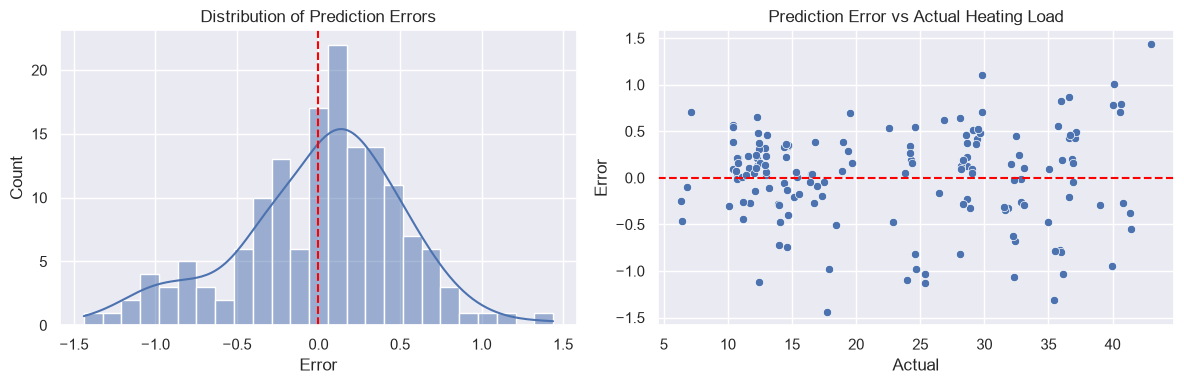

In [162]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(
    data=error_analysis,
    x="Error",
    bins=25,
    kde=True,
    ax=axes[0]
)
axes[0].axvline(0, color="red", linestyle="--")
axes[0].set_title("Distribution of Prediction Errors")

sns.scatterplot(
    data=error_analysis,
    x="Actual",
    y="Error",
    ax=axes[1]
)
axes[1].axhline(0, color="red", linestyle="--")
axes[1].set_title("Prediction Error vs Actual Heating Load")

fig.tight_layout()
plt.show()

## 9. Permutation Feature Importance

In [166]:
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_squared_error, make_scorer
from sklearn.base import BaseEstimator, RegressorMixin

class KerasRegressorWrapper(BaseEstimator, RegressorMixin):
    def __init__(self, model):
        self.model = model

    def fit(self, X, y=None):
        # The Keras model is already trained
        self.n_features_in_ = X.shape[1]
        return self

    def predict(self, X):
        return self.model.predict(X, verbose=0).ravel()


wrapped_model = KerasRegressorWrapper(model)

scorer = make_scorer(
    mean_squared_error,
    greater_is_better=False
)

importance = permutation_importance(
    wrapped_model,
    x_test_sc,
    np.asarray(y_test),
    scoring=scorer,
    n_repeats=10,
    random_state=42
)

importance_df = pd.DataFrame({
    "Feature": X.columns,
    "Importance": importance.importances_mean,
    "Std": importance.importances_std
}).sort_values("Importance", ascending=False)

importance_df

,Feature,Importance,Std
4,Overall Height,262.096669,22.790797
2,Wall Area,41.301975,6.188163
6,Glazing Area,14.605099,1.588244
0,Relative Compactness,13.662302,1.163846
3,Roof Area,13.601651,1.648571
1,Surface Area,7.335240,0.758017
7,Glazing Area Distribution,1.211357,0.151230
5,Orientation,0.065315,0.031069


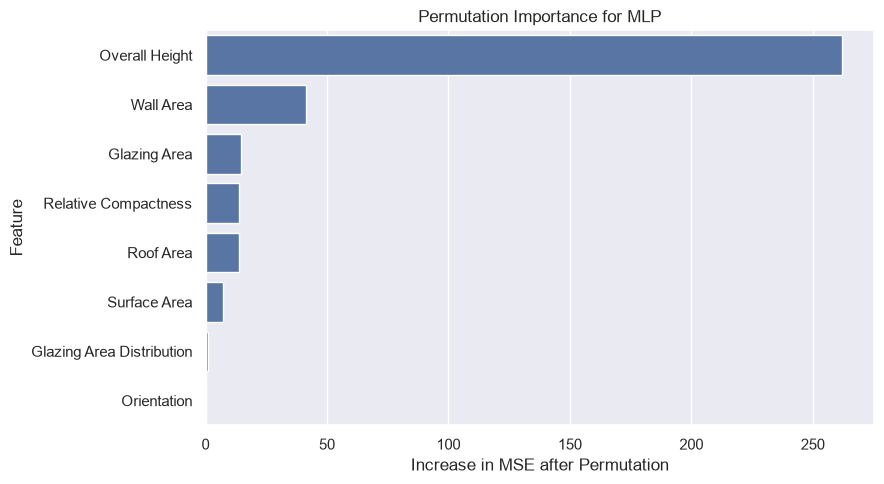

In [167]:
fig, ax = plt.subplots(figsize=(9, 5))

sns.barplot(
    data=importance_df,
    x="Importance",
    y="Feature",
    ax=ax
)

ax.set_title("Permutation Importance for MLP")
ax.set_xlabel("Increase in MSE after Permutation")
ax.set_ylabel("Feature")

plt.tight_layout()
plt.show()

## 10. Comparing Feature Subsets

In [168]:
feature_sets = {
    "Full Model": list(X.columns),
    "Two Features": ["Overall Height", "Wall Area"],
    "Four Features": [
        "Overall Height",
        "Wall Area",
        "Glazing Area",
        "Relative Compactness"
    ]
}

In [169]:
def build_mlp(input_dim):
    model = keras.Sequential([
        layers.Input(shape=(input_dim,)),
        layers.Dense(64, activation="relu"),
        layers.Dense(32, activation="relu"),
        layers.Dense(1)
    ])

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.001),
        loss="mse"
    )

    return model

In [170]:
results = []

for name, features in feature_sets.items():
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(42)

    # Select the same train/test rows for each model
    Xtr = X_train[features].copy()
    Xte = X_test[features].copy()

    scaler = StandardScaler()
    Xtr_scaled = scaler.fit_transform(Xtr)
    Xte_scaled = scaler.transform(Xte)

    model = build_mlp(len(features))

    early_stopping = keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=30,
        restore_best_weights=True
    )

    model.fit(
        Xtr_scaled,
        np.asarray(y_train).ravel(),
        validation_split=0.2,
        epochs=500,
        batch_size=32,
        callbacks=[early_stopping],
        verbose=0
    )

    predictions = model.predict(Xte_scaled, verbose=0).ravel()
    actual = np.asarray(y_test).ravel()

    results.append({
        "Model": name,
        "Number of Features": len(features),
        "MAE": mean_absolute_error(actual, predictions),
        "RMSE": np.sqrt(mean_squared_error(actual, predictions)),
        "R2": r2_score(actual, predictions)
    })

results_df = pd.DataFrame(results)
results_df.round(4)

,Model,Number of Features,MAE,RMSE,R2
0,Full Model,8,0.3923,0.5060,0.9975
1,Two Features,2,2.3466,3.2910,0.8961
2,Four Features,4,0.3990,0.5288,0.9973


## 11. Conclusions

- The MLP substantially outperformed the Linear Regression baseline on the held-out test split.
- Five-fold cross-validation provides an additional check beyond a single train/test split.
- Feature ablation suggests that a smaller feature set may retain much of the full model’s performance, while the two-feature model performs noticeably worse.
- These results apply to this dataset and evaluation setup; they do not guarantee performance on building designs outside the dataset’s range.
